## 👗️ Clothing Review Rating Prediction

Given *reviews of women's clothing*, let's try to predict whether the rating associated with the review will be **5-star** or not.

We will use a TensorFlow recurrent neural network to make our predictions.

Data source: https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import tensorflow as tf

I0000 00:00:1793718238.989936    6848 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793718239.487716    6848 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793718242.190465    6848 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
data = pd.read_csv('archive/Womens Clothing E-Commerce Reviews.csv')
data

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


### Preprocessing

In [8]:
# Drop rows with missing reviews
missing_review_rows = data[data['Review Text'].isna()].index

data = data.drop(missing_review_rows, axis=0).reset_index(drop=True)

In [10]:
# Use only the review and rating columns
y = data['Rating'].copy()
X = data['Review Text'].copy()

In [11]:
y

0        4
1        5
2        3
3        5
4        5
        ..
22636    5
22637    3
22638    3
22639    3
22640    5
Name: Rating, Length: 22641, dtype: int64

In [12]:
X

0        Absolutely wonderful - silky and sexy and comf...
1        Love this dress!  it's sooo pretty.  i happene...
2        I had such high hopes for this dress and reall...
3        I love, love, love this jumpsuit. it's fun, fl...
4        This shirt is very flattering to all due to th...
                               ...                        
22636    I was very happy to snag this dress at such a ...
22637    It reminds me of maternity clothes. soft, stre...
22638    This fit well, but the top was very see throug...
22639    I bought this dress for a wedding i have this ...
22640    This dress in a lovely platinum is feminine an...
Name: Review Text, Length: 22641, dtype: object

In [13]:
X.isna().sum()

np.int64(0)

In [15]:
# Make y a binary target
y = y.apply(lambda x: 1 if x == 5 else 0)
y

0        0
1        1
2        0
3        1
4        1
        ..
22636    1
22637    0
22638    0
22639    0
22640    1
Name: Rating, Length: 22641, dtype: int64

In [16]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=1)

In [17]:
X_train

9232     This dress is adorable. it simply did not fi o...
13974    The fit was not flattering at all, but the wor...
17979    I bought this top in both colors. the fit is p...
9586     This is even cuter in person than it is in the...
9358     I couldn't believe there weren't more reviews ...
                               ...                        
10955    Pretty color, but i was hoping for a thicker, ...
17289    This sweater coat is a keeper. yes it runs lar...
5192     Should have ordered the xl instead of the larg...
12172    I really like this denim jacket with the plaid...
235      Love pilcro, love the stripes and the length -...
Name: Review Text, Length: 15848, dtype: object

In [18]:
X_train.shape

(15848,)

In [19]:
# Learn the vocabulary
tokenizer = Tokenizer()
tokenizer.fit_on_texts(X_train)

In [21]:
len(tokenizer.word_index)

12750

In [23]:
# Find the size of the vocabulary
vocab_length = len(tokenizer.word_index) + 1
print("Vocab Length:", vocab_length)

Vocab Length: 12751


In [24]:
# Convert the reviews text into sequences of integers
X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

In [26]:
# Find the maximum sequence length
max_seq_length = np.max(list(map(lambda x: len(x), X_train)))
print("Maximum sequence length:", max_seq_length)

Maximum sequence length: 116


In [27]:
# Pad the sequences to be uniform length
X_train = pad_sequences(X_train, maxlen=max_seq_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_seq_length, padding='post')

In [30]:
X_train

array([[  7,  18,   6, ...,   0,   0,   0],
       [  1,  26,  15, ...,   0,   0,   0],
       [  2,  74,   7, ...,   0,   0,   0],
       ...,
       [349,  23,  52, ...,   0,   0,   0],
       [  2,  50,  28, ...,   0,   0,   0],
       [ 22, 515,  22, ...,   0,   0,   0]],
      shape=(15848, 116), dtype=int32)

In [31]:
X_train.shape

(15848, 116)

### Training

In [36]:
inputs = tf.keras.Input(shape=(X_train.shape[1], ))

x = tf.keras.layers.Embedding(
    input_dim = vocab_length,
    output_dim = 128,
    input_length = max_seq_length
)(inputs)

x = tf.keras.layers.Bidirectional(tf.keras.layers.GRU(256, return_sequences=True, activation='tanh'))(x)

x = tf.keras.layers.Flatten()(x)

outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

history = model.fit(
    X_train,
    y_train,
    validation_split = 0.2,
    batch_size = 32,
    epochs = 100,
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor = 'val_loss',
            patience = 3,
            restore_best_weights = True
        )
    ]
)

Epoch 1/100
397/397 ━━━━━━━━━━━━━━━━━━━━ 233s 580ms/step - accuracy: 0.7437 - loss: 0.5208 - val_accuracy: 0.7861 - val_loss: 0.4866
Epoch 2/100
397/397 ━━━━━━━━━━━━━━━━━━━━ 234s 590ms/step - accuracy: 0.8475 - loss: 0.3565 - val_accuracy: 0.7741 - val_loss: 0.5197
Epoch 3/100
397/397 ━━━━━━━━━━━━━━━━━━━━ 244s 614ms/step - accuracy: 0.9277 - loss: 0.1837 - val_accuracy: 0.7489 - val_loss: 0.6669
Epoch 4/100
397/397 ━━━━━━━━━━━━━━━━━━━━ 238s 600ms/step - accuracy: 0.9730 - loss: 0.0775 - val_accuracy: 0.7543 - val_loss: 0.9562


### Results

In [37]:
model.evaluate(X_test, y_test)

213/213 ━━━━━━━━━━━━━━━━━━━━ 35s 163ms/step - accuracy: 0.7793 - loss: 0.4914


[0.4914286732673645, 0.7793316841125488]

In [38]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 116)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 116, 128)       │     1,632,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 116, 512)       │       592,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 59392)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        59,393 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,853,253 (26.14 MB)

 Trainable params: 2,284,417 (8.71 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,568,836 (17.43 MB)

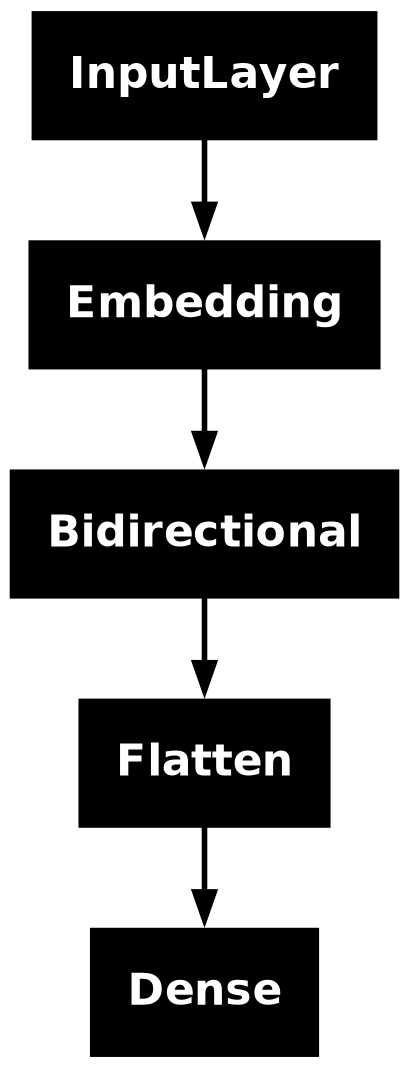

In [39]:
tf.keras.utils.plot_model(model)